# Profile molecular and QC support across PBMC platforms with GAUGE

**Your task.** How does the predictability of Leiden labels change with resolution, and how much of that change is visible in gene expression and measured quality-control (QC) features? Generate three candidate partitions for each platform, score the same partition from two views, then read the profiles side by side.

This example uses peripheral blood mononuclear cells (PBMC1) from Ding et al. (GEO GSE132044). The pinned teaching asset samples 1,000 cells with existing source annotations from each of 10x Chromium (v3) and Drop-seq, without balancing cell types. The platforms contain separate cells. The supplied cell-type labels do not enter clustering or evaluation.

## 0. Install GAUGE and place the data beside this notebook

Use Python 3.10 or newer. In a terminal on macOS or Linux, create and activate an environment.

```bash
python -m venv .venv
source .venv/bin/activate
```

In Windows PowerShell, activate it with `.venv\Scripts\Activate.ps1`.

Install the software and tutorial dependencies from the public GAUGE repository. If you already have a checkout, run the install command from its root.

```bash
git clone https://github.com/zhanglabtools/gauge-sc.git
cd gauge-sc
python -m pip install ".[tutorial]" jupyterlab
```

To install from a downloaded wheel, pass its local path with the tutorial extra. This example uses version `0.1.0a2`.

```bash
python -m pip install "./gauge_sc-0.1.0a2-py3-none-any.whl[tutorial]" jupyterlab
```

Download **`ding_pbmc.h5ad`** (about 6.5 MB) from [tutorial-data-v1](https://github.com/zhanglabtools/gauge-sc/releases/tag/tutorial-data-v1) and put it beside this notebook. You can also run this command from the notebook folder.

```bash
curl -fLO https://github.com/zhanglabtools/gauge-sc/releases/download/tutorial-data-v1/ding_pbmc.h5ad
```

From that folder, run `jupyter lab` and select the installed Python environment as the notebook kernel. If the data are elsewhere, set `data_dir` below to their containing directory. GAUGE verifies the pinned local file. The first cell should print **2,000 cells × 33,694 features** and list 1,000 observed cells per platform.

In [1]:
import os
from pathlib import Path

from IPython.display import display

import gauge_sc as gauge

data_dir = Path(os.environ.get("GAUGE_TUTORIAL_DATA") or ".")
source = gauge.datasets.load_example("ding_pbmc", data_dir=data_dir, download=False)
platform_key = "Method"
qc_columns = ["nUMI", "nGene", "percent.mito"]
print(f"GAUGE {gauge.__version__} · {source.n_obs:,} cells × {source.n_vars:,} features")
display(source.obs.groupby(platform_key, observed=True).size().to_frame("Cells"))

Matplotlib is building the font cache; this may take a moment.


GAUGE 0.1.0a2 · 2,000 cells × 33,694 features


,Cells
Method,
10x Chromium (v3),1000
Drop-seq,1000


## 1. Build candidate labels and define the two views

Within each platform, normalize and log-transform the supplied expression counts, choose 2,000 highly variable genes, compute 30 principal components (PCs), and build one 15-neighbor graph. Use this fixed graph to cluster at Leiden resolutions 0.3, 0.6 and 1.0. The resulting group counts can differ even at the same resolution.

The **molecular view** uses those 30 expression PCs. The **QC view** uses the source measurements `nUMI` (captured molecule count), `nGene` (detected genes) and `percent.mito` (mitochondrial proportion on its supplied scale). We log-transform the two count covariates when building the QC view. Keep each platform's original QC values and candidate labels fixed while the views are evaluated.

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import scanpy as sc

sc.set_figure_params(dpi=110, frameon=False)
resolutions = [0.3, 0.6, 1.0]
candidate_keys = [f"leiden_{resolution}" for resolution in resolutions]
methods = ["10x Chromium (v3)", "Drop-seq"]
prepared = {}
for method in methods:
    sample = source[source.obs[platform_key].eq(method)].copy()
    sc.pp.normalize_total(sample, target_sum=10_000)
    sc.pp.log1p(sample)
    sc.pp.highly_variable_genes(sample, n_top_genes=2_000, flavor="seurat")
    sc.pp.pca(sample, n_comps=30, mask_var="highly_variable", random_state=0)
    sc.pp.neighbors(sample, n_neighbors=15, use_rep="X_pca", random_state=0)
    for resolution, key in zip(resolutions, candidate_keys):
        sc.tl.leiden(
            sample,
            resolution=resolution,
            key_added=key,
            random_state=0,
            flavor="igraph",
            directed=False,
            n_iterations=2,
        )
    prepared[method] = sample

## 2. Score the same labels from expression and QC

ITCA measures how much information about the fixed labels is predictable from each view. GAUGE uses five stratified test folds, paired across views for each candidate, and computes ITCA here from pooled held-out predictions. Each group contributes its recall weighted by that group's information mass. Thus the number and relative sizes of groups both matter.

Read one row at a time. The molecular and QC scores in a row refer to exactly the same cells, candidate labels and test folds. A high QC score means the measured QC variables predict the labels. It motivates checking group-level QC distributions and independent markers before giving the groups a biological interpretation.

In [3]:
profile_parts = []
resolution_for = dict(zip(candidate_keys, resolutions))
views = {
    "molecular": {"obsm": "X_pca"},
    "qc": {"obs": qc_columns, "log1p": ["nUMI", "nGene"]},
}
for method, sample in prepared.items():
    result = gauge.evaluate(
        sample, groupby=candidate_keys, views=views,
        n_splits=5, random_state=0, aggregation="pooled",
    )
    profile_parts.append(result.table.assign(platform=method))
profiles = pd.concat(profile_parts, ignore_index=True)
profiles["resolution"] = profiles["groupby"].map(resolution_for)
score_table = profiles.pivot(
    index=["platform", "resolution", "n_groups", "effective_groups"],
    columns="view",
    values="itca",
).reset_index()
score_table.columns.name = None
display(score_table.round(3))

,platform,resolution,n_groups,effective_groups,molecular,qc
0,10x Chromium (v3),0.3,7,6.222,1.791,1.055
1,10x Chromium (v3),0.6,8,6.444,1.831,1.082
2,10x Chromium (v3),1.0,11,9.735,2.129,1.105
3,Drop-seq,0.3,5,3.568,1.201,0.677
4,Drop-seq,0.6,6,5.035,1.500,0.677
5,Drop-seq,1.0,9,7.105,1.676,0.726


## 3. Read the two profiles together

The panels share the same ITCA scale. Each dot shows one tested partition, at its observed number of groups. Use the table for the corresponding Leiden resolution and effective group count. The effective count is the number of equally sized groups with the same label entropy. Two partitions with the same raw count can have different effective counts if their group sizes differ.

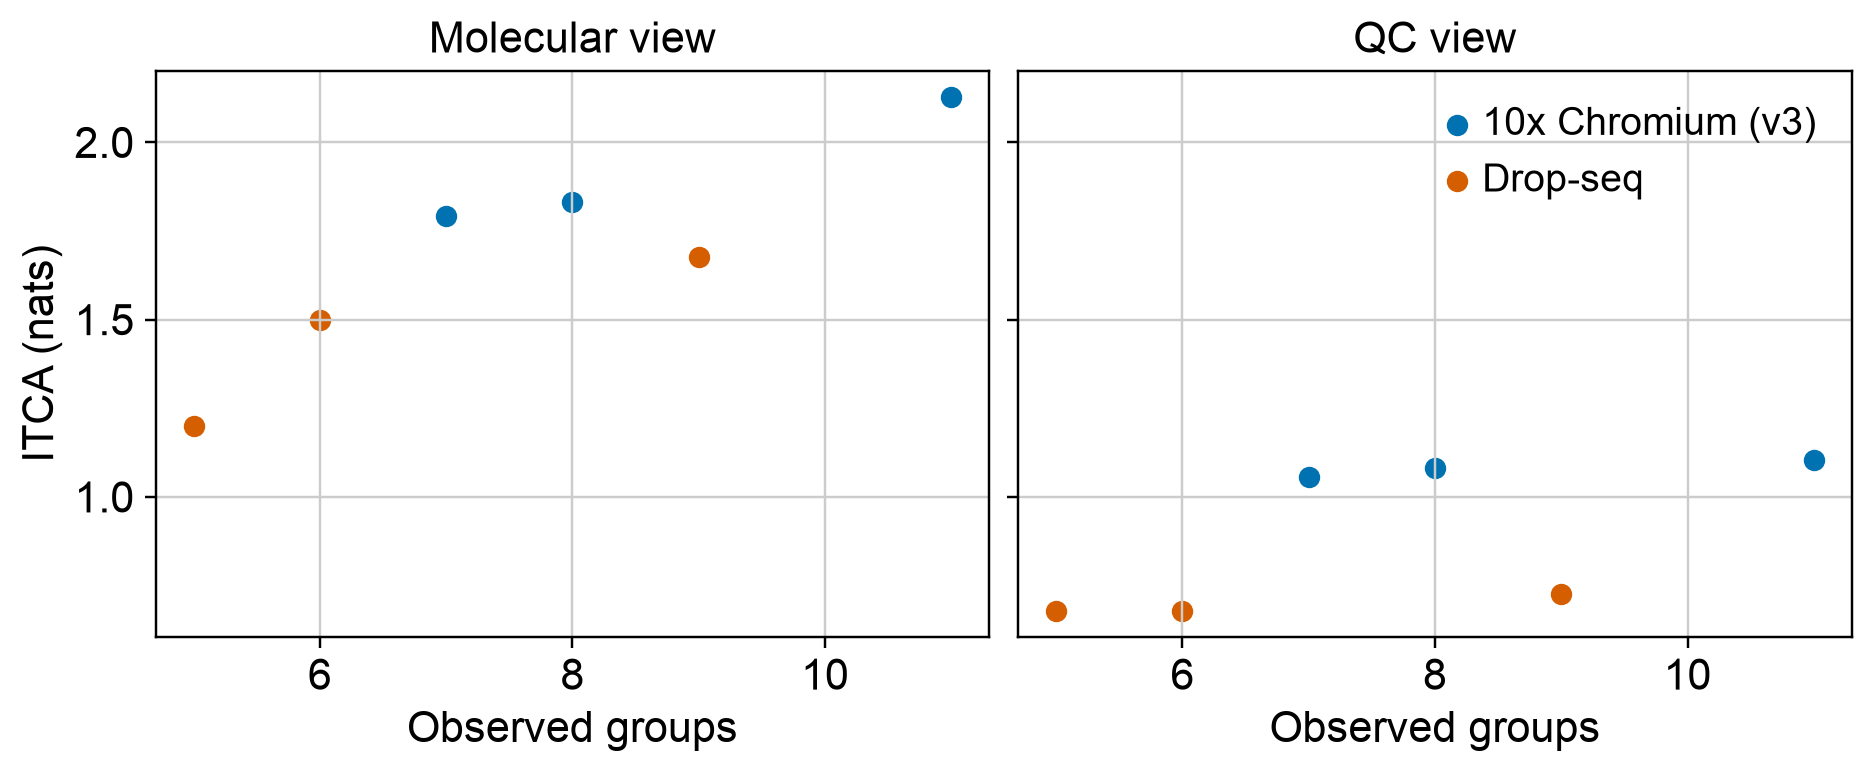

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.4), sharex=True, sharey=True,
                         layout="constrained")
colors = {"10x Chromium (v3)": "#0072B2", "Drop-seq": "#D55E00"}
for ax, view in zip(axes, ["molecular", "qc"]):
    for method in methods:
        part = profiles.loc[profiles["view"].eq(view) & profiles["platform"].eq(method)]
        ax.scatter(part["n_groups"], part["itca"], label=method, color=colors[method])
    ax.set(xlabel="Observed groups", title=f"{view.capitalize()} view" if view != "qc" else "QC view")
axes[0].set_ylabel("ITCA (nats)")
axes[1].legend(frameon=False)
plt.show()

In [5]:
for method in methods:
    tested = score_table.loc[score_table["platform"].eq(method)].set_index("resolution")
    first, last = tested.loc[0.3], tested.loc[1.0]
    print(
        f"{method}, resolution 0.3 to 1.0 ({int(first.n_groups)} to "
        f"{int(last.n_groups)} groups): molecular ITCA {first.molecular:.3f} "
        f"to {last.molecular:.3f} ({last.molecular - first.molecular:+.3f}); "
        f"QC ITCA {first.qc:.3f} to {last.qc:.3f} ({last.qc - first.qc:+.3f}) nats."
    )

10x Chromium (v3), resolution 0.3 to 1.0 (7 to 11 groups): molecular ITCA 1.791 to 2.129 (+0.338); QC ITCA 1.055 to 1.105 (+0.050) nats.
Drop-seq, resolution 0.3 to 1.0 (5 to 9 groups): molecular ITCA 1.201 to 1.676 (+0.475); QC ITCA 0.677 to 0.726 (+0.049) nats.


The printed comparison uses the actual scores at the low and high endpoints of the tested resolution range. Compare the signed changes **within** a platform. A larger increase in molecular ITCA than in QC ITCA means the overall label set gained more expression predictability over that interval. Leiden can reassign cells between resolutions, so this comparison describes the whole partition. An increase in both is a cue to inspect where the gains occur and which QC features vary by group.

Across platforms, the cells, graphs and resulting partitions differ. Equal resolution or equal raw group count only aligns one setting or summary. Treat differences across the two sets of dots as descriptive profiles of this sample. A platform-quality ranking would need a comparison designed around matched coverage and the same scientific target.

## Apply the profiles to your own AnnData

Use one sample with existing candidate label columns and numeric, finite QC columns in `obs`, and a shared expression representation in `obsm`. The code below runs on one of the prepared tutorial samples. Change the data object, candidate columns, representation and QC names. List only nonnegative raw QC count columns under `log1p`. For a second platform, run the same evaluation on that platform's own sample and compare the profiles with its cells and partitions in mind.

In [6]:
user_adata = prepared["10x Chromium (v3)"]  # Or sc.read_h5ad("my_sample.h5ad").
groupings = ["leiden_0.3", "leiden_1.0"]  # Your candidate columns in .obs.
embedding = "X_pca"  # Your shared molecular representation in .obsm.
umi, genes, mito = "nUMI", "nGene", "percent.mito"  # Your QC columns in .obs.

user_result = gauge.evaluate(
    user_adata, groupby=groupings, n_splits=5, random_state=0, aggregation="pooled",
    views={
        "molecular": {"obsm": embedding},
        "qc": {"obs": [umi, genes, mito], "log1p": [umi, genes]},
    },
)
display(user_result.table.pivot(index=["groupby", "n_groups"], columns="view", values="itca").round(3))

,view,molecular,qc
groupby,n_groups,,
leiden_0.3,7,1.791,1.055
leiden_1.0,11,2.129,1.105


## Go further

The [paper reproduction guide](../../docs/paper-reproduction.md) leads to the full Figure 3 profiles and their effective-group-count summaries. This tutorial evaluates three resolutions per platform on the 2,000-cell teaching asset.

[Use GAUGE with your agent](../../docs/agents.md) and request paired molecular and QC scoring within each `ding_pbmc` platform. Ask it to identify an interval with a clear molecular change and report the accompanying QC change on the same partitions.